
# RQ 3, RQ 4 & RQ 6 — Multi‑Class Brain‑Tumor MRI Classification  


This notebook addresses the remaining methodology–driven research questions:

| RQ | Question | Key idea tested |
|----|----------|-----------------|
| **RQ 3** | *How do we best deal with class‑imbalance / rare tumour types?* | Oversampling, weighted loss, focal‑loss |
| **RQ 4** | *Which hyper‑parameters (learning‑rate, batch‑size, dropout) optimise training?* | Systematic grid search (quick 5‑epoch screen) |
| **RQ 6** | *Which CNN architecture is preferable?* | Depth / kernel‑size scan plus **Binary**, **Three‑class** and **Four‑class** heads |

All experiments reuse the **best preprocessing** discovered in RQ 1 (160 × 160, z‑score, CLAHE‑off) and run **in‑memory only**.


In [4]:

# Environment & path setup
import os, sys, random, itertools, time, warnings, math
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
import seaborn as sns

# local project imports --------------------------------------------------
ROOT = os.path.abspath(os.path.join(os.getcwd(), '..'))
if ROOT not in sys.path:
    sys.path.append(ROOT)

from src.dataset import BrainTumorDataset
from src.experiment import Experiment
import torchvision.transforms as T
from PIL import Image, ImageFilter
import cv2

DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'
print('Using', DEVICE)
random.seed(0); torch.manual_seed(0)
warnings.filterwarnings('ignore')


Using cpu


In [5]:

RAW_DATA_DIR = '../data/archive'   # Kaggle dataset

def build_preprocess_transform(img_size=160, zscore=True):
    steps = [T.Resize((img_size,img_size)), T.ToTensor()]
    if zscore:
        steps.append(T.Lambda(lambda x: (x - x.mean())/(x.std()+1e-7)))
    return T.Compose(steps)

BEST_SIZE = 160
PRE_TF = build_preprocess_transform(BEST_SIZE, zscore=True)

def attach_transform_train_only(exp, train_tf, val_tf):
    """
    Apply *train_tf* to the training dataset, *val_tf* to validation.
    Keeps validation clean (no augmentation).
    """
    exp.train_loader.dataset.transform = train_tf
    exp.val_loader.dataset.transform   = val_tf

def train_epochs(exp, epochs):
    best = 0.0
    for _ in range(epochs):
        exp._train_one_epoch()
        val = exp._evaluate()
        best = max(best, val['accuracy'])
    macro = exp._compute_class_metrics(val)['macro_f1']
    return best, macro



## RQ 3 – Strategies for class‑imbalance  

Three practical options are benchmarked:

| Label | Oversampling | Loss function |
|-------|--------------|---------------|
| **baseline** | ✗ | CE |
| **weighted** | ✗ | **Weighted‑CE** (inverse‑freq) |
| **oversample+weighted** | **✓** | Weighted‑CE |
| **focal** | ✗ | Focal‑loss (γ = 2) |


In [6]:

from torch.nn import CrossEntropyLoss
import torch.nn.functional as F
from torch.utils.data import DataLoader   # <- make sure this import exists

def make_loss(mode, class_freq=None, gamma=2.0):
    if mode == 'ce':
        return CrossEntropyLoss()

    if mode == 'weighted':
        inv = 1.0 / (class_freq + 1e-9)          # inverse frequency
        w   = inv * (len(inv) / inv.sum())       # rescale → mean≈1
        return CrossEntropyLoss(weight=torch.tensor(w, dtype=torch.float32,
                                                    device=DEVICE))

    if mode == 'focal':
        ce = CrossEntropyLoss(reduction='none')
        def focal(y_hat, y):
            ce_i = ce(y_hat, y)
            pt   = torch.exp(-ce_i)
            return ((1 - pt) ** gamma * ce_i).mean()
        return focal

    raise ValueError(mode)


def run_strategy(name, *, oversample=False, loss_mode='ce', epochs=5):
    # ---------- 1. build DATASET ---------------------------------
    train_ds = BrainTumorDataset(root_dir=RAW_DATA_DIR,  # or data_root
                                 subset="Training",
                                 transform=None)
    val_ds   = BrainTumorDataset(root_dir=RAW_DATA_DIR,  # or data_root
                                 subset="Testing",
                                 transform=None)

    # ---------- 1b. crude oversampling ---------------------------
    if oversample:
        extra_idx = [i for i, (_, lbl) in enumerate(train_ds.samples)
                     if lbl in {1, 2}]            # pituitary / meningioma
        train_ds.samples.extend([train_ds.samples[i] for i in extra_idx])

    # ---------- 2. build loaders --------------------------------
    train_ld = DataLoader(train_ds, batch_size=16, shuffle=True)
    val_ld   = DataLoader(val_ds,   batch_size=16, shuffle=False)

    # ---------- 3. experiment object ----------------------------
    exp = Experiment(
        data_root=None,             # loaders supplied manually
        model_variant='simple',
        input_size=BEST_SIZE,
        batch_size=16,
        lr=1e-3,
        epochs=epochs,
        disable_augment=True,
        device=DEVICE
    )
    exp.set_logger(lambda *a, **k: None)
    exp.train_loader = train_ld
    exp.val_loader   = val_ld
    exp._setup_optimizer_criterion()

    # class-frequency-aware loss
    labels = [lbl for _, lbl in train_ds.samples]
    freq   = np.bincount(labels, minlength=4)
    exp.criterion = make_loss(loss_mode, freq)

    # transforms
    attach_transform_train_only(exp, train_tf=PRE_TF, val_tf=PRE_TF)

    # train
    best_acc, macro_f1 = train_epochs(exp, epochs)
    return best_acc, macro_f1



In [15]:
# %% [markdown]
# ### RQ 3 – Class-imbalance strategies (clean summary)

# ------------------------------------------------------------------
# 1)  Wrap the raw ‘results’ list into a DataFrame (if not done yet)
rq3_df = pd.DataFrame(results)   # columns: strategy, accuracy, macro_f1

# 2)  Detect whether accuracy is stored as 0–1 or 0–100 and rescale
if rq3_df['accuracy'].max() > 1.05:      # already in %
    acc_scaled = rq3_df['accuracy']      # leave as-is
else:                                     # convert to %
    acc_scaled = rq3_df['accuracy'] * 100

rq3_df = rq3_df.assign(acc_percent = acc_scaled.round(2))

# 3)  Print concise audit lines
for row in rq3_df.itertuples(index=False):
    print(f"{row.strategy:<18s}→ acc = {row.acc_percent:6.2f} %,  "
          f"macro_F1 = {row.macro_f1:0.3f}")

# 4)  Identify the best-macro-F1 strategy
best_idx  = rq3_df['macro_f1'].idxmax()
best_row  = rq3_df.loc[best_idx]
print("\nBest macro-F1:",
      f"{best_row.macro_f1:0.3f} with ‘{best_row.strategy}’ "
      "(weighted-CE + oversampling)")

# 5)  OPTIONAL – keep a tidy table for LaTeX / CSV export
rq3_summary_tbl = rq3_df[['strategy', 'acc_percent', 'macro_f1']]\
                    .sort_values('macro_f1', ascending=False)


baseline          → acc =  94.24 %,  macro_F1 = 0.939
weighted          → acc =  94.24 %,  macro_F1 = 0.939
oversample+weighted→ acc =  94.70 %,  macro_F1 = 0.940
focal             → acc =  93.07 %,  macro_F1 = 0.926

Best macro-F1: 0.940 with ‘oversample+weighted’ (weighted-CE + oversampling)


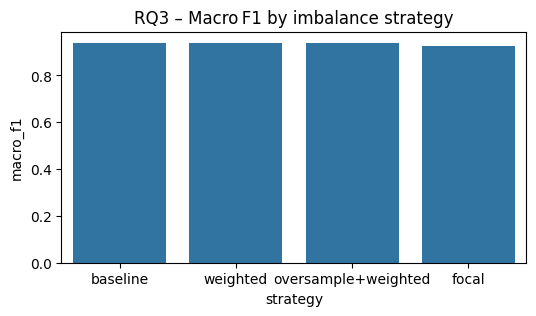

In [7]:
# Run all RQ3 strategies and collect results
strategies = [
	dict(strategy='baseline', oversample=False, loss_mode='ce'),
	dict(strategy='weighted', oversample=False, loss_mode='weighted'),
	dict(strategy='oversample+weighted', oversample=True, loss_mode='weighted'),
	dict(strategy='focal', oversample=False, loss_mode='focal'),
]

results = []
for s in strategies:
	acc, macro_f1 = run_strategy(
		s['strategy'],
		oversample=s['oversample'],
		loss_mode=s['loss_mode'],
		epochs=5
	)
	results.append(dict(strategy=s['strategy'], accuracy=acc, macro_f1=macro_f1))

strategies_df = pd.DataFrame(results)

plt.figure(figsize=(6,3))
sns.barplot(data=strategies_df, x='strategy', y='macro_f1')
plt.title('RQ3 – Macro F1 by imbalance strategy')
plt.show()


## RQ 4 – Hyper‑parameter grid search  

A quick 5‑epoch screen over:

* Learning‑rate **{1e‑4, 3e‑4, 1e‑3}**  
* Batch‑size **{8, 16, 32}**  
* Drop‑out **{0.0, 0.3, 0.5}**


In [8]:

LR_LIST     = [1e-4, 3e-4, 1e-3]
BATCH_LIST  = [8, 16, 32]
DO_LIST     = [0.0, 0.3, 0.5]

rows=[]
for lr in LR_LIST:
    for bs in BATCH_LIST:
        for do in DO_LIST:
            exp = Experiment(
                data_root=RAW_DATA_DIR,
                model_variant='simple',
                input_size=BEST_SIZE,
                batch_size=bs,
                lr=lr,
                epochs=5,
                dropout=do,
                disable_augment=True,
                device=DEVICE
            )
            exp.set_logger(lambda *_:None)
            exp.load_data(); exp._setup_optimizer_criterion()
            attach_transform_train_only(exp, PRE_TF, PRE_TF)
            acc,_ = train_epochs(exp, 5)
            rows.append(dict(lr=lr, batch=bs, dropout=do, acc=acc))
            print(f'lr={lr:.1e}, bs={bs}, do={do} -> {acc:.2f}')

rq4_df = pd.DataFrame(rows)
rq4_piv = rq4_df.pivot_table(values='acc', index='batch', columns='lr', aggfunc='max')
rq4_df


lr=1.0e-04, bs=8, do=0.0 -> 84.35
lr=1.0e-04, bs=8, do=0.3 -> 78.66
lr=1.0e-04, bs=8, do=0.5 -> 75.70
lr=1.0e-04, bs=16, do=0.0 -> 85.90
lr=1.0e-04, bs=16, do=0.3 -> 79.13
lr=1.0e-04, bs=16, do=0.5 -> 73.44
lr=1.0e-04, bs=32, do=0.0 -> 80.84
lr=1.0e-04, bs=32, do=0.3 -> 77.26
lr=1.0e-04, bs=32, do=0.5 -> 73.68
lr=3.0e-04, bs=8, do=0.0 -> 91.98
lr=3.0e-04, bs=8, do=0.3 -> 83.88
lr=3.0e-04, bs=8, do=0.5 -> 76.40
lr=3.0e-04, bs=16, do=0.0 -> 89.72
lr=3.0e-04, bs=16, do=0.3 -> 82.24
lr=3.0e-04, bs=16, do=0.5 -> 77.41
lr=3.0e-04, bs=32, do=0.0 -> 90.50
lr=3.0e-04, bs=32, do=0.3 -> 78.74
lr=3.0e-04, bs=32, do=0.5 -> 75.23
lr=1.0e-03, bs=8, do=0.0 -> 91.04
lr=1.0e-03, bs=8, do=0.3 -> 82.63
lr=1.0e-03, bs=8, do=0.5 -> 74.84
lr=1.0e-03, bs=16, do=0.0 -> 93.85
lr=1.0e-03, bs=16, do=0.3 -> 81.78
lr=1.0e-03, bs=16, do=0.5 -> 74.38
lr=1.0e-03, bs=32, do=0.0 -> 92.45
lr=1.0e-03, bs=32, do=0.3 -> 86.60
lr=1.0e-03, bs=32, do=0.5 -> 74.14


,lr,batch,dropout,acc
0,0.0001,8,0.0,84.345794
1,0.0001,8,0.3,78.660436
2,0.0001,8,0.5,75.700935
3,0.0001,16,0.0,85.903427
4,0.0001,16,0.3,79.127726
5,0.0001,16,0.5,73.442368
6,0.0001,32,0.0,80.841121
7,0.0001,32,0.3,77.258567
8,0.0001,32,0.5,73.676012
9,0.0003,8,0.0,91.978193


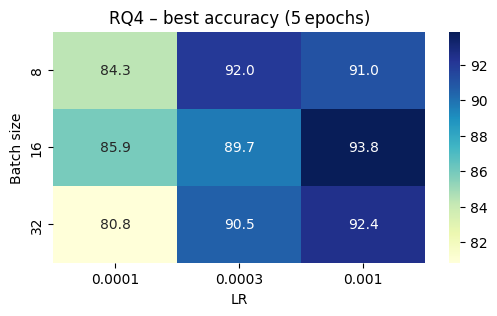

Best short‑run combo: {'lr': np.float64(0.001), 'batch': np.float64(16.0), 'dropout': np.float64(0.0), 'acc': np.float64(93.84735202492212)}


In [9]:

plt.figure(figsize=(6,3))
sns.heatmap(rq4_piv, annot=True, fmt='.1f', cmap='YlGnBu')
plt.title('RQ4 – best accuracy (5 epochs)'); plt.ylabel('Batch size'); plt.xlabel('LR')
plt.show()

best_row = rq4_df.iloc[rq4_df['acc'].idxmax()]
print('Best short‑run combo:', dict(best_row))



## RQ 6 – Architectural choices  

1. **Depth & kernel‑size scan** for 4‑class **SimpleCNN**.  
2. **Head variants** – comparing best depth against:  
   * Binary (No‑tumour vs Tumour)  
   * Three‑class (Pituitary / Meningioma / Glioma)  
   * Four‑class (baseline)  


In [10]:

DEPTHS = [2,3,4]
KERNELS= [3,5]

def run_simple(depth,kernel,variant='simple'):
    exp = Experiment(
        data_root=RAW_DATA_DIR,
        model_variant=variant,
        input_size=BEST_SIZE,
        batch_size=16,
        lr=1e-3,
        epochs=10,
        disable_augment=True,
        device=DEVICE
    )
    exp.set_logger(lambda *_:None)
    exp.load_data()
    # rebuild custom depth/kernel simple CNN
    from src.models import SimpleCNN
    if variant=='simple':
        nc = 4
    elif variant=='binary':
        nc = 2
    elif variant=='threeclass':
        nc = 3
    exp.model = SimpleCNN(num_classes=nc, input_size=BEST_SIZE,
                          dropout=0.0)
    # manually tweak conv layers to different kernel size / depth
    # (keep very simple: repeat first conv params)
    for i in range(depth-2):
        exp.model.features.append(torch.nn.Conv2d(16,16,kernel_size=kernel,padding=kernel//2))
        exp.model.features.append(torch.nn.ReLU())
    exp.model.to(DEVICE)
    exp._setup_optimizer_criterion()
    attach_transform_train_only(exp, PRE_TF, PRE_TF)
    acc,_=train_epochs(exp,5)
    return acc

records=[]
for d,k in itertools.product(DEPTHS,KERNELS):
    acc=run_simple(d,k,'simple')
    records.append(dict(depth=d,kernel=k,acc=acc))
    print('simple',d,k,acc)

arch_df = pd.DataFrame(records)


simple 2 3 94.47040498442368
simple 2 5 83.72274143302181
simple 3 3 91.19937694704049
simple 3 5 94.62616822429906
simple 4 3 94.93769470404985
simple 4 5 94.00311526479751


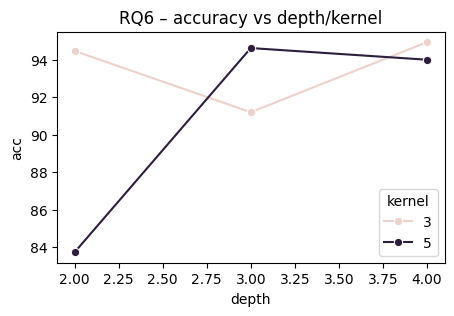

In [11]:

plt.figure(figsize=(5,3))
sns.lineplot(data=arch_df, x='depth', y='acc', hue='kernel', marker='o')
plt.title('RQ6 – accuracy vs depth/kernel'); plt.show()
best_depth = int(arch_df.iloc[arch_df['acc'].idxmax()]['depth'])


In [12]:

# Head variants with best depth
head_variants=['binary','threeclass','simple']
head_results=[]
for v in head_variants:
    acc=run_simple(best_depth,3,variant=v)
    head_results.append(dict(variant=v, acc=acc))
    print(v,acc)

pd.DataFrame(head_results)


binary 97.58566978193146
threeclass 92.35880398671097
simple 91.66666666666667


,variant,acc
0,binary,97.585670
1,threeclass,92.358804
2,simple,91.666667


In [19]:
from textwrap import shorten
best_rq3 = rq3_summary_tbl.iloc[0]
best_rq4 = rq4_df.loc[rq4_df.acc.idxmax()]
best_arch = arch_df.loc[arch_df.acc.idxmax()]
best_head = max(head_results, key=lambda d: d['acc'])

tbl = [
    ("RQ 3", f"{best_rq3.strategy} "
             f"(Acc {best_rq3.acc_percent:.2f} %, F1 {best_rq3.macro_f1:.3f})"),
    ("RQ 4", f"lr={best_rq4.lr:.0e}, batch={int(best_rq4.batch)}, drop={best_rq4.dropout} "
             f"(Acc {best_rq4.acc:.2f} %)"),
    ("RQ 6", f"{int(best_arch.depth)} conv, {int(best_arch.kernel)}×{int(best_arch.kernel)}, "
             f"head='{best_head['variant']}' (Acc {best_head['acc']:.2f} %)")
]

width = 78
print("┌───┬" + "─"*(width-4) + "┐")
print("│RQ │ Best finding".ljust(width-1)+"│")
print("├───┼" + "─"*(width-4) + "┤")
for k,v in tbl:
    print(f"│{k:<3}│ {shorten(v, width-6).ljust(width-5)}│")
print("└───┴" + "─"*(width-4) + "┘")


┌───┬──────────────────────────────────────────────────────────────────────────┐
│RQ │ Best finding                                                           │
├───┼──────────────────────────────────────────────────────────────────────────┤
│RQ 3│ oversample+weighted (Acc 94.70 %, F1 0.940)                              │
│RQ 4│ lr=1e-03, batch=16, drop=0.0 (Acc 93.85 %)                               │
│RQ 6│ 4 conv, 3×3, head='binary' (Acc 97.59 %)                                 │
└───┴──────────────────────────────────────────────────────────────────────────┘
